## A/B Testing for Landing Page Optimization

Conducted an A/B testing analysis on ~294K user sessions to evaluate whether a new landing page improved conversion rates compared to the existing page. Performed exploratory data analysis, calculated conversion metrics, and applied a two-proportion Z-test to determine statistical significance between control and treatment groups. Visualized results using Python (Pandas, Matplotlib, Seaborn) to generate insights that support data-driven product decisions.

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.proportion import proportions_ztest

In [3]:
df = pd.read_csv("ab_data.csv")
df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


## Basic Data Exploration

In [4]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df['group'].value_counts())
print(df['landing_page'].value_counts())

(294478, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB
None
user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64
group
treatment    147276
control      147202
Name: count, dtype: int64
landing_page
old_page    147239
new_page    147239
Name: count, dtype: int64


## Check Conversion Distribution

In [5]:
print(df['converted'].value_counts())
conversion_rate = df['converted'].mean()
print("Overall Conversion Rate:", conversion_rate)

converted
0    259241
1     35237
Name: count, dtype: int64
Overall Conversion Rate: 0.11965919355605512


## Conversion Rate by Group

In [6]:
conversion_by_group = df.groupby('group')['converted'].mean()
print(conversion_by_group)

group
control      0.120399
treatment    0.118920
Name: converted, dtype: float64


## Count Users per Group

In [7]:
group_counts = df.groupby('group')['converted'].count()
print(group_counts)

group
control      147202
treatment    147276
Name: converted, dtype: int64


## Visualize Conversion Rate

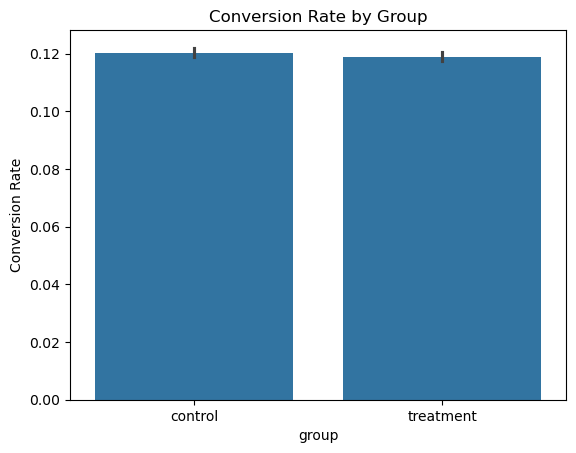

In [8]:
sns.barplot(x='group', y='converted', data=df)
plt.title("Conversion Rate by Group")
plt.ylabel("Conversion Rate")
plt.show()

## Prepare Data for Z-Test

In [9]:
control = df[df['group'] == 'control']
treatment = df[df['group'] == 'treatment']
control_conversions = control['converted'].sum()
treatment_conversions = treatment['converted'].sum()
control_users = control.shape[0]
treatment_users = treatment.shape[0]

## Run Two-Proportion Z-Test

In [10]:
conversions = np.array([control_conversions, treatment_conversions])
visitors = np.array([control_users, treatment_users])
z_stat, p_value = proportions_ztest(conversions, visitors)
print("Z-statistic:", z_stat)
print("P-value:", p_value)

Z-statistic: 1.2369217547321678
P-value: 0.21611613269757501


## Interpret Result

In [11]:
alpha = 0.05

if p_value < alpha:
    print("Reject Null Hypothesis: New page performs differently")
else:
    print("Fail to Reject Null Hypothesis: No significant difference")

Fail to Reject Null Hypothesis: No significant difference


## Conversion Rate Comparison

In [12]:
control_rate = control_conversions / control_users
treatment_rate = treatment_conversions / treatment_users
print("Control Conversion Rate:", control_rate)
print("Treatment Conversion Rate:", treatment_rate)

Control Conversion Rate: 0.12039917935897611
Treatment Conversion Rate: 0.11891957956489856


## Visualization of Conversion Rates

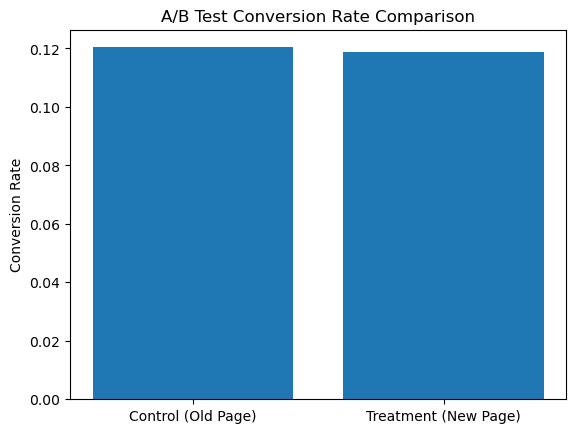

In [13]:
rates = [control_rate, treatment_rate]
labels = ["Control (Old Page)", "Treatment (New Page)"]
plt.bar(labels, rates)
plt.ylabel("Conversion Rate")
plt.title("A/B Test Conversion Rate Comparison")
plt.show()


## Time Analysis

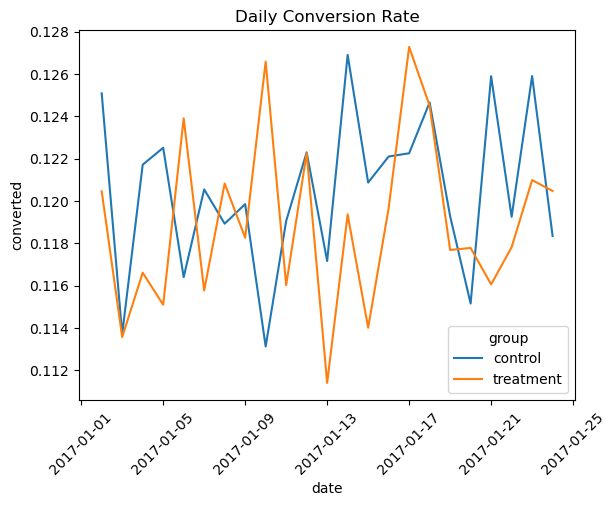

In [14]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['date'] = df['timestamp'].dt.date
daily_conversion = df.groupby(['date','group'])['converted'].mean().reset_index()
sns.lineplot(data=daily_conversion, x='date', y='converted', hue='group')
plt.title("Daily Conversion Rate")
plt.xticks(rotation=45)
plt.show()